In [435]:
import os
import sys
sys.path.append(r"C:\Users\acostamendoza\projects\distance-project")
from path_setup import setup_project_path
setup_project_path()
from src.utils import create_new_result_dir
from src.LinearExperiment import LinearDevice, LinearPlots
import matplotlib.pyplot as plt
import numpy as np

%load_ext autoreload
%autoreload 2

data_dir = r'D:/data-distance-coding-project/processed-data/250411_SAM033_only-rotation/'
session = r'250411_SAM033_3'
session_path = os.path.join(data_dir, session)

L = LinearDevice(session_path, response_mode='dFF-zscore')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Directory results already exists
Successfully loaded activity data
Stimulus file found
Synchronized stimulus and activity
Repeat stimulus on length distribution:
    19 repeats have length 11
    1 repeats have length 12
Set stimulus on length: 11


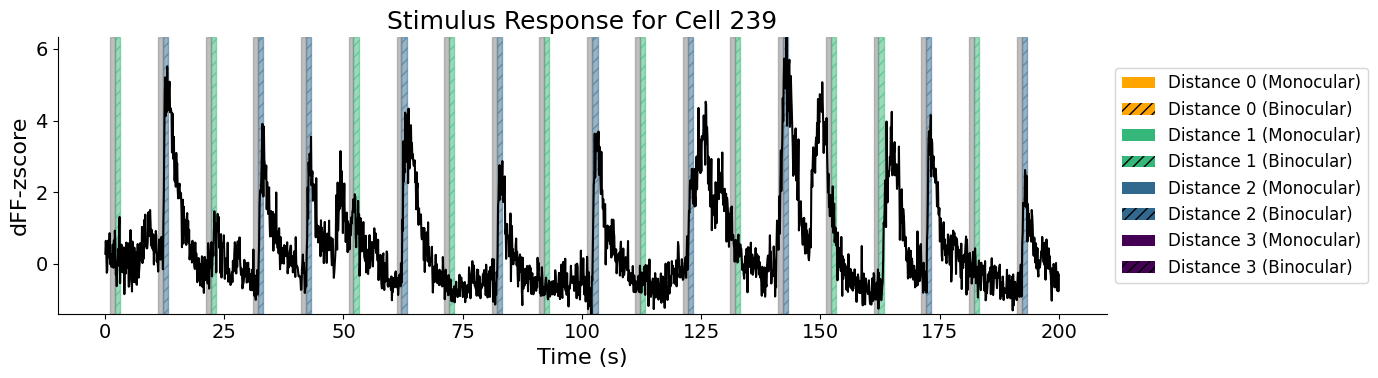

In [437]:
LinearPlots(L).plot_stimulus_response(repeats=[0,20], cell=239)

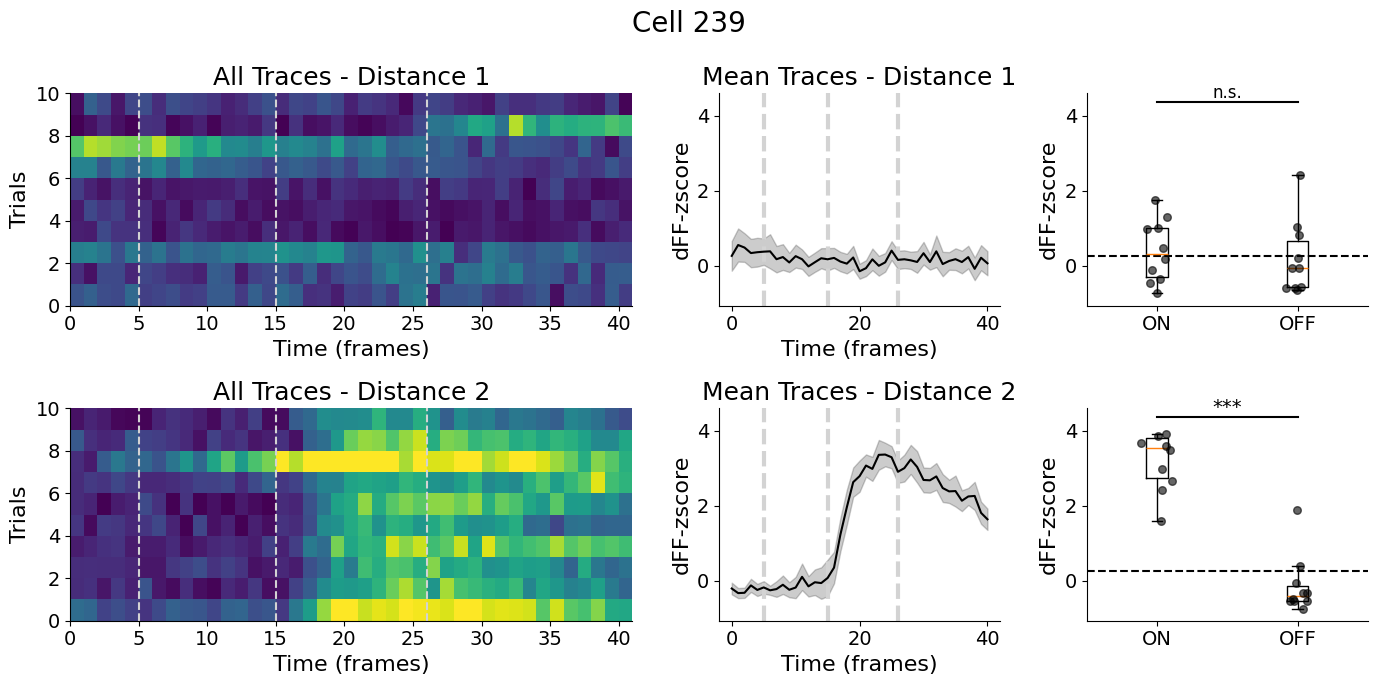

In [438]:
plots = LinearPlots(L)
fig = plots.plot_all_traces_colormap(239, distance=[1, 2])

In [411]:
# cell response
fig_path = create_new_result_dir(L.results_path, r'cell_response')

for cell in L.suite2p_id:
    fig = LinearPlots(L).plot_all_traces_colormap(cell, distance=[0,1,2,3])
    filename = os.path.join(fig_path, f'cell_{cell}.png')
    fig.savefig(filename)
    plt.close(fig)

Directory cell_response already exists


# Now for responsivness

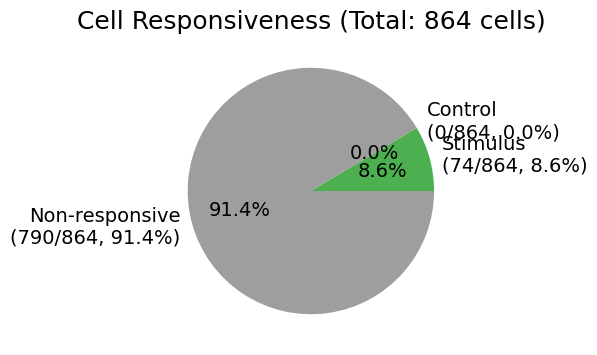

In [418]:
cells_responsive_stimulus = []
cells_responsive_control = []
non_responsive_cells = []
for cell in L.suite2p_id:
    is_responsive_stimulus = L.analyze_cell_responsiveness(cell, None)[0]
    if is_responsive_stimulus:
        cells_responsive_stimulus.append(cell)
    elif not is_responsive_stimulus:
        non_responsive_cells.append(cell)

# make a pie chart showing the percentage and number of responsive and unresponsive cells
# Calculate total number of cells
total_cells = len(L.suite2p_id)

# Create data for pie chart
responsive_stimulus_count = len(cells_responsive_stimulus)
responsive_control_count = len(cells_responsive_control)
non_responsive_count = len(non_responsive_cells)

# Create labels with counts and percentages
labels = [
    f'Stimulus\n({responsive_stimulus_count}/{total_cells}, {responsive_stimulus_count/total_cells:.1%})',
    f'Control\n({responsive_control_count}/{total_cells}, {responsive_control_count/total_cells:.1%})',
    f'Non-responsive\n({non_responsive_count}/{total_cells}, {non_responsive_count/total_cells:.1%})'
]

fig, ax = plt.subplots(figsize=(8, 4))
ax.pie([responsive_stimulus_count, responsive_control_count, non_responsive_count], 
       labels=labels, 
       autopct='%1.1f%%',
       colors=['#4CAF50', '#F44336', '#9E9E9E'])
ax.set_title(f'Cell Responsiveness (Total: {total_cells} cells)')
plt.show()
# save pie chart
fig.savefig(os.path.join(L.results_path, 'pie_chart_responsive_cells_stimulus.png'))
plt.close(fig)


In [ ]:
L

In [408]:
# plot responsive cells to stimuls
fig_path = create_new_result_dir(L.results_path, r'responsive_cells_stimulus')
for cell in cells_responsive_stimulus:
    print(f'Cell {cell} ({cells_responsive_stimulus.index(cell)+1}/{len(cells_responsive_stimulus)})', end='\r')
    fig = LinearPlots(L).plot_all_traces_colormap(cell)
    filename = os.path.join(fig_path, f'cell_{cell}.png')
    fig.savefig(filename)
    plt.close(fig)

Directory responsive_cells_stimulus already exists


In [392]:
# plot non-responsive cells to stimulus and control
fig_path = create_new_result_dir(L.results_path, r'non_responsive_cells_stimulus')
for cell in cells_responsive_control:
    print(f'Cell {cell} ({cells_responsive_control.index(cell)+1}/{len(cells_responsive_control)})', end='\r')
    fig = LinearPlots(L).plot_all_traces_colormap(cell)
    filename = os.path.join(fig_path, f'cell_{cell}.png')
    fig.savefig(filename)
    plt.close(fig)
for cell in non_responsive_cells:
    print(f'Cell {cell} ({non_responsive_cells.index(cell)+1}/{len(non_responsive_cells)})', end='\r')
    fig = LinearPlots(L).plot_all_traces_colormap(cell)
    filename = os.path.join(fig_path, f'cell_{cell}.png')
    fig.savefig(filename)
    plt.close(fig)

Creating directory: non_responsive_cells_stimulus


# Plot location of the responsive cells


[1, 11, 15, 19, 28, 29, 31, 35, 40, 45, 54, 60, 61, 62, 64, 66, 74, 92, 102, 107, 111, 119, 124, 127, 136, 137, 142, 146, 149, 158, 159, 194, 203, 208, 222, 237, 264, 269, 276, 277, 279, 288, 294, 299, 307, 324, 341, 346, 361, 380, 383, 392, 398, 403, 406, 412, 423, 425, 432, 467, 486, 510, 595, 625, 647, 672, 685, 811, 825, 828, 840, 851, 855, 862]


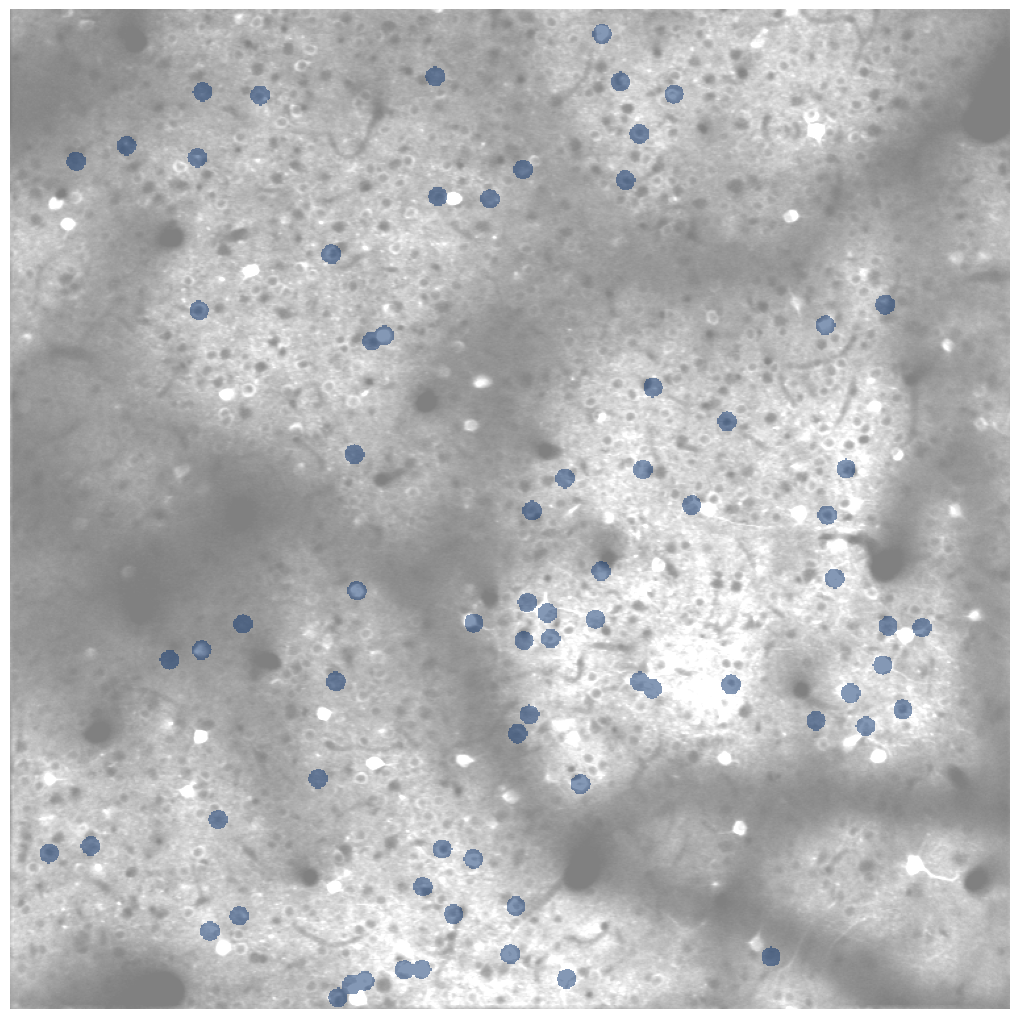

In [419]:
# get the indices of the cells with osi > 0.5

# Load the stat and ops files from the current folder
stat = np.load(L.activity_path + r'\stat.npy', allow_pickle=True)
ops = np.load(L.activity_path + r'\ops.npy', allow_pickle=True).item()

im = np.zeros((ops['Ly'], ops['Lx']))

# # get cells which osi > 0.5
tuned_cells = cells_responsive_stimulus
tuned_cells_idx = []
for cell in tuned_cells:
    tuned_cells_idx.append(np.where(L.suite2p_id == cell)[0][0])

print(tuned_cells_idx)

if len(tuned_cells_idx) > 0:
    for cell in tuned_cells_idx:
        
        ypix = stat[cell]['ypix'][~stat[cell]['overlap']]
        xpix = stat[cell]['xpix'][~stat[cell]['overlap']]
        # find the index of the cell in the cell_properties_df
        
        # Calculate the center of the cell
        center_y = np.mean(ypix)
        center_x = np.mean(xpix)
        
        # Create a circle mask with radius 10
        y, x = np.ogrid[:ops['Ly'], :ops['Lx']]
        dist_from_center = np.sqrt((x - center_x)**2 + (y - center_y)**2)
        circle_mask = dist_from_center <= 8
        
        # Add the circle to the image
        # im[circle_mask] = cell_properties_df.loc[cell_index, 'preferred_orientation'] # Set pixels to preferred orientation (normalized to 0-1)
        im[circle_mask] = 1
    

mean_img = ops['meanImg']
vmin = np.percentile(mean_img, 1)
vmax = np.percentile(mean_img, 99)

# Create the figure for display
plt.figure(figsize=(10, 10))
plt.imshow(ops['refImg'], alpha=0.5, cmap='gray', vmin=vmin, vmax=vmax)
# Create a mask for non-zero values
mask = im > 0
# Create a masked array where zeros are masked out
masked_im = np.ma.masked_where(im == 0, im)

plt.imshow(masked_im, alpha=0.5, vmin=0, vmax=1, cmap='Blues')
plt.axis('off')  # Turn off axes
plt.tight_layout(pad=0)  # Remove padding
# have colorbar to the right of the image

# Create a new figure specifically for saving
fig = plt.figure(figsize=(10, 10))
plt.imshow(ops['refImg'], alpha=0.6, cmap='gray', vmin=vmin, vmax=vmax)
plt.imshow(masked_im, alpha=1, vmin=0, vmax=1, cmap='Blues')
plt.axis('off')  # Turn off axes
plt.tight_layout(pad=0)  # Remove padding
plt.savefig(os.path.join(L.results_path, 'responsive_cells_stimulus_location.png'))
plt.close(fig)
